# 04 · Meta-analysis, directions and forest plots (Sections 4.2–4.3, Figs 3–6)
Pools the per-unit estimates of notebook 03 with a DerSimonian–Laird random-effects model. The 95% prediction interval uses a t distribution with k − 2 degrees of freedom: it is the range expected for the effect in a new project, and the basis of the transportability claims. Requires `estimates11.csv` from notebook 03.

In [1]:
# On Google Colab, uncomment the next line first:
# !pip install -q dowhy==0.14 statsmodels networkx
import warnings, numpy as np, pandas as pd, networkx as nx, statsmodels.api as sm
from scipy import stats
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

# Data source: Song & Minku (TSE 2022) replication package. Set BASE to a local folder to work offline.
BASE = "https://raw.githubusercontent.com/sunnysong14/ContinualPerformanceValidityTSE2022/main/data/"
Y, T = "days_to_first_fix", "author_date_unix_timestamp"

PROJECTS = {"brackets": "Brackets", "broadleaf": "Broadleaf", "camel": "Camel", "corefx": "CoreFX",
            "django": "Django", "fabric8": "Fabric8", "jgroup": "JGroup", "nova": "Nova", "rails": "Rails",
            "rust": "Rust", "tensorflow": "TensorFlow", "vscode": "VSCode", "wp-calypso": "WP-Calypso"}
# Projects on which the 33-edge graph is informative and not rejected (Section 4.1)
COMPATIBLE = ["brackets", "camel", "corefx", "django", "fabric8", "nova",
              "rails", "rust", "tensorflow", "vscode", "wp-calypso"]
METRICS = [T, "exp", "rexp", "fix", "ns", "nf", "sexp", "lt", "nuc", "ndev", "age", "la", "ld", "entropy", Y]


def load(name, horizon_q=0.9, return_info=False):
    """Defect-inducing commits of one project, with the right-censored tail removed.

    A commit made within `horizon` of the last commit in the data has had less time to be fixed than
    the project's 90th-percentile defect lifetime, so it is excluded (Section 2.2).
    """
    raw = pd.read_csv(f"{BASE}{name}.csv")
    raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed")].rename(columns={"entrophy": "entropy"})
    bug = raw[raw.contains_bug == 1]
    horizon_days = bug[Y].quantile(horizon_q)
    kept = bug[bug[T] <= bug[T].max() - horizon_days * 86400]
    df = kept.replace([np.inf, -np.inf], np.nan).dropna(subset=METRICS).reset_index(drop=True)
    df["fix"] = df["fix"].astype(float)
    if return_info:
        return df, dict(project=PROJECTS[name], all_commits=len(raw), defect_inducing=len(bug),
                        horizon_days=round(horizon_days), after_censoring=len(kept), analysed=len(df))
    return df


In [2]:
E = pd.read_csv("estimates11.csv")
TREATMENTS = ["ndev", "entropy", "sexp", "rexp"]

def meta(y, se):
    v = se ** 2; w = 1 / v; k = len(y)
    fe = (w * y).sum() / w.sum(); Q = (w * (y - fe) ** 2).sum(); C = w.sum() - (w ** 2).sum() / w.sum()
    tau2 = max(0.0, (Q - (k - 1)) / C); ws = 1 / (v + tau2)
    mu = (ws * y).sum() / ws.sum(); se_mu = np.sqrt(1 / ws.sum())
    h = stats.t.ppf(0.975, k - 2) * np.sqrt(tau2 + se_mu ** 2)
    return dict(k=k, pooled=mu, se=se_mu, lo=mu - 1.96 * se_mu, hi=mu + 1.96 * se_mu,
                p=2 * stats.norm.sf(abs(mu / se_mu)), tau2=tau2, I2=max(0.0, (Q - (k - 1)) / Q) * 100, Q=Q,
                pi_lo=mu - h, pi_hi=mu + h, weights=100 * ws / ws.sum())

META = {t: meta(E[E.treatment == t].beta.values, E[E.treatment == t].se.values) for t in TREATMENTS}
table7 = pd.DataFrame({t: {k: v for k, v in m.items() if k != "weights"} for t, m in META.items()}).T
table7["PI_excludes_0"] = (table7.pi_lo > 0) | (table7.pi_hi < 0)
table7.to_csv("meta11.csv"); table7

,k,pooled,se,lo,hi,p,tau2,I2,Q,pi_lo,pi_hi,PI_excludes_0
ndev,11.0,-0.354480,0.188131,-0.723218,0.014257,0.059535,0.296673,93.741390,159.779885,-1.658053,0.949092,False
entropy,11.0,-23.279369,8.424784,-39.791946,-6.766792,0.005724,744.249914,97.843058,463.619418,-87.868884,41.310146,False
sexp,11.0,-0.000171,0.001349,-0.002815,0.002473,0.899001,0.000012,89.703251,97.118035,-0.008627,0.008284,False
rexp,11.0,-0.005153,0.005237,-0.015418,0.005112,0.325125,0.000113,62.800456,26.882050,-0.031977,0.021671,False


## Table 5 · Direction of each significant effect

In [3]:
def arrow(r): return "n.s." if r.p >= 0.05 else ("↓" if r.beta < 0 else "↑")
dirs = E.assign(d=E.apply(arrow, axis=1), name=E.project.map(PROJECTS)).pivot(index="name", columns="treatment", values="d")[TREATMENTS]
dirs["significant / 4"] = (dirs != "n.s.").sum(axis=1)
dirs.loc["↓ / ↑ / n.s."] = [f"{(dirs[t] == '↓').sum()} / {(dirs[t] == '↑').sum()} / {(dirs[t] == 'n.s.').sum()}"
                            for t in TREATMENTS] + [int(dirs["significant / 4"].sum())]
dirs

treatment,ndev,entropy,sexp,rexp,significant / 4
name,,,,,
Brackets,n.s.,n.s.,n.s.,↓,1
Camel,↓,n.s.,↑,↓,3
CoreFX,↓,↓,n.s.,n.s.,2
Django,n.s.,↓,↑,n.s.,2
Fabric8,↑,↓,↓,n.s.,3
Nova,↑,n.s.,n.s.,n.s.,1
Rails,↓,↓,n.s.,n.s.,2
Rust,↓,n.s.,n.s.,n.s.,1
TensorFlow,↓,↓,↑,n.s.,3


## Forest plots (Figs 3–6)

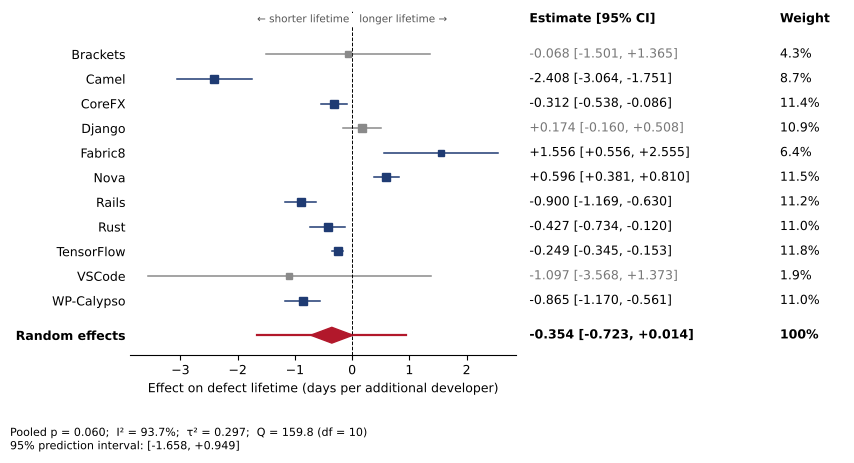

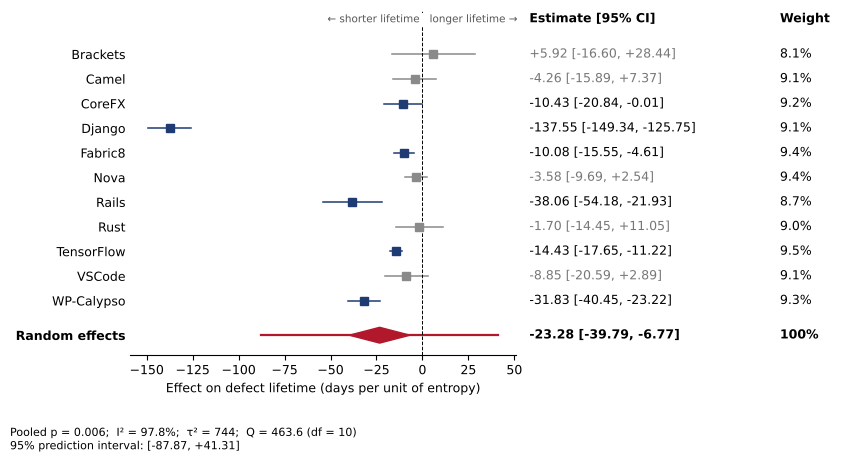

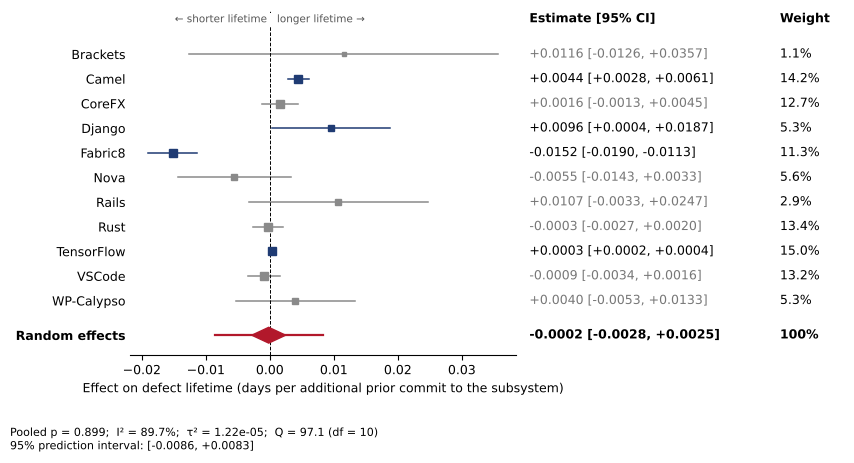

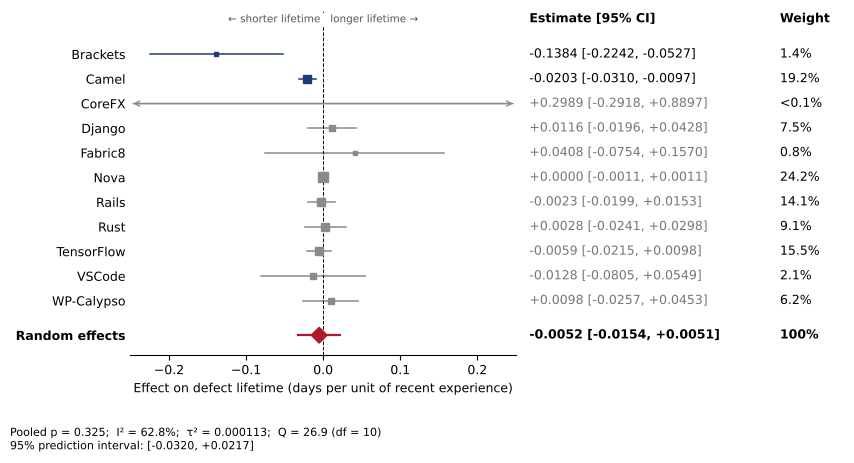

In [4]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9})
SPEC = {"ndev": (3, "days per additional developer", "{:+.3f}", None),
        "entropy": (4, "days per unit of entropy", "{:+.2f}", None),
        "sexp": (5, "days per additional prior commit to the subsystem", "{:+.4f}", None),
        "rexp": (6, "days per unit of recent experience", "{:+.4f}", (-0.25, 0.25))}

def forest(t):
    fig_no, unit, fmt, xlim = SPEC[t]; m = META[t]
    d = E[E.treatment == t].assign(name=lambda x: x.project.map(PROJECTS)).sort_values("name")
    k = len(d); ys = np.arange(k)[::-1] + 2; yp = 0.6
    fig, (ax, tx) = plt.subplots(1, 2, figsize=(8.6, 4.6), gridspec_kw={"width_ratios": [1.5, 1.25], "wspace": 0.02})
    w = d.project.map(dict(zip(E[E.treatment == t].project, m["weights"]))).values
    for y, r, wi in zip(ys, d.itertuples(), w):
        c = "#1f3b73" if r.p < 0.05 else "#8a8a8a"; lo, hi = r.lo, r.hi
        if xlim:
            if hi > xlim[1]: ax.annotate("", xy=(xlim[1], y), xytext=(max(lo, xlim[0]), y), arrowprops=dict(arrowstyle="->", color=c)); hi = None
            if lo < xlim[0]: ax.annotate("", xy=(xlim[0], y), xytext=(min(r.hi, xlim[1]), y), arrowprops=dict(arrowstyle="->", color=c)); lo = None
        if lo is not None and hi is not None: ax.plot([lo, hi], [y, y], color=c, lw=1.1)
        ax.plot(r.beta, y, "s", ms=2.5 + 0.9 * np.sqrt(wi), color=c, zorder=4)
    ax.plot([m["pi_lo"], m["pi_hi"]], [yp, yp], color="#b2182b", lw=1.6)
    ax.fill([m["lo"], m["pooled"], m["hi"], m["pooled"]], [yp, yp + 0.32, yp, yp - 0.32], color="#b2182b", zorder=3)
    ax.axvline(0, color="black", lw=0.7, ls="--")
    if xlim: ax.set_xlim(*xlim)
    ax.set_yticks(list(ys) + [yp]); ax.set_yticklabels(list(d.name) + ["Random effects"])
    ax.get_yticklabels()[-1].set_fontweight("bold")
    ax.set_ylim(-0.2, k + 2.8); ax.set_xlabel(f"Effect on defect lifetime ({unit})")
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.text(0, k + 2.3, "← shorter lifetime   longer lifetime →", ha="center", fontsize=7.5, color="#555",
            bbox=dict(fc="white", ec="none", pad=1))
    tx.set_xlim(0, 1); tx.set_ylim(ax.get_ylim()); tx.axis("off")
    tx.text(0.02, k + 2.3, "Estimate [95% CI]", fontweight="bold"); tx.text(0.80, k + 2.3, "Weight", fontweight="bold")
    for y, r, wi in zip(ys, d.itertuples(), w):
        tx.text(0.02, y, f"{fmt.format(r.beta)} [{fmt.format(r.lo)}, {fmt.format(r.hi)}]", va="center",
                color="black" if r.p < 0.05 else "#777")
        tx.text(0.80, y, f"{wi:.1f}%" if wi >= 0.1 else "<0.1%", va="center")
    tx.text(0.02, yp, f"{fmt.format(m['pooled'])} [{fmt.format(m['lo'])}, {fmt.format(m['hi'])}]", va="center", fontweight="bold")
    tx.text(0.80, yp, "100%", va="center", fontweight="bold")
    fig.text(0.02, 0.015, f"Pooled p = {m['p']:.3f};  I² = {m['I2']:.1f}%;  τ² = {m['tau2']:.3g};  Q = {m['Q']:.1f} (df = {m['k'] - 1})\n"
                          f"95% prediction interval: [{fmt.format(m['pi_lo'])}, {fmt.format(m['pi_hi'])}]", fontsize=8)
    fig.subplots_adjust(left=0.16, right=0.99, top=0.97, bottom=0.22)
    for ext in ("pdf", "png"):
        fig.savefig(f"fig{fig_no}_forest_{t}.{ext}", dpi=300)
    plt.show()

for t in TREATMENTS:
    forest(t)